# Freight Rate Prediction: CatBoost vs. XGBoost

This notebook builds a reproducible freight-rate forecasting workflow. It uses a chronological holdout, compares CatBoost and XGBoost on identical rows, selects the lower-MAE model, refits it on all labeled data, and creates both scorer-ready deliverables.

**Selection rule:** lowest holdout MAE. RMSE and R² are supporting diagnostics. No random split or target-derived feature is used.

## 1. Setup

The workflow uses one fixed seed and bounded, CPU-friendly model configurations. Input and output paths follow the repository layout and the supplied scorer contract.

In [1]:
from pathlib import Path
import hashlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
SEED = 42
TARGET = "posted_rate"
DATE_ORIGIN = pd.Timestamp("2025-01-01")
POSITIVE_FLOOR = 0.01
ROOT = Path.cwd()

TRAIN_PATH = ROOT / "train-test.csv"
VALIDATION_PATH = ROOT / "validation.csv"
TEMPLATE_PATH = ROOT / "validation-predictions-template.csv"
DECEMBER_SOURCE_PATH = ROOT / "december-chart-inputs.csv"
SCORE_PATH = ROOT / "Score.py"
SCORE_HASH_BEFORE = hashlib.sha256(SCORE_PATH.read_bytes()).hexdigest()

np.random.seed(SEED)

## 2. Load and validate the data

Missing predictors are retained for imputation. Dropping them would discard useful labeled rows and could bias later dates.

In [2]:
train_raw = pd.read_csv(TRAIN_PATH)
validation_raw = pd.read_csv(VALIDATION_PATH)
prediction_template = pd.read_csv(TEMPLATE_PATH)
december_raw = pd.read_csv(DECEMBER_SOURCE_PATH)

required_train = {
    "load_id", "pickup", "delivery", "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon", "distance", "equipment", "weight",
    "date", "market_index", "quote_signal", TARGET,
}
required_validation = required_train - {TARGET}
required_december = {"pickup", "delivery", "distance", "equipment", "weight", "date", "predicted_rate"}

assert required_train.issubset(train_raw.columns)
assert required_validation.issubset(validation_raw.columns)
assert required_december == set(december_raw.columns)
assert train_raw["load_id"].is_unique and validation_raw["load_id"].is_unique
assert len(validation_raw) == len(prediction_template) == 12_000
assert prediction_template["load_id"].is_unique
assert set(prediction_template["load_id"]) == set(validation_raw["load_id"])
assert len(december_raw) == 31

for frame in (train_raw, validation_raw, december_raw):
    frame["date"] = pd.to_datetime(frame["date"], errors="raise")

assert train_raw["date"].max() < validation_raw["date"].min()
assert train_raw["date"].min() == pd.Timestamp("2025-01-01")
assert train_raw["date"].max() == pd.Timestamp("2025-10-31")
assert set(december_raw["date"]) == set(pd.date_range("2025-12-01", "2025-12-31"))

print("Shapes:", {"train": train_raw.shape, "validation": validation_raw.shape, "december": december_raw.shape})
display(train_raw.head(3))

Shapes: {'train': (48000, 14), 'validation': (12000, 13), 'december': (31, 7)}


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54


In [3]:
missing = train_raw.isna().sum().loc[lambda values: values > 0].rename("missing_rows").to_frame()
print("Training date range:", train_raw["date"].min().date(), "to", train_raw["date"].max().date())
print("Future prediction range:", validation_raw["date"].min().date(), "to", validation_raw["date"].max().date())
display(missing)
display(train_raw[TARGET].describe().to_frame().T)

Training date range: 2025-01-01 to 2025-10-31
Future prediction range: 2025-11-01 to 2025-12-31


,missing_rows
weight,300
market_index,374


,count,mean,std,min,25%,50%,75%,max
posted_rate,48000.0,2373.980682,1486.493245,57.22,1251.555,2030.76,3330.75,25533.0


## 3. Feature engineering

The features are deliberately compact:

- calendar trend, weekday, month, and smooth annual seasonality;
- pickup, delivery, equipment, and route identity;
- coordinate spans for geographic direction and coverage;
- distance/weight density;
- distance interactions with the supplied market and quote signals.

The last interactions are useful because freight rates are naturally distance-scaled. The reduced feature set excludes columns unavailable in the separate December file.

In [4]:
CATEGORICAL_FEATURES = ["pickup", "delivery", "equipment", "route"]
REDUCED_NUMERIC_FEATURES = [
    "distance", "weight", "date_ordinal", "month", "weekday",
    "dayofyear_sin", "dayofyear_cos", "distance_per_1000_lb",
]
FULL_NUMERIC_FEATURES = REDUCED_NUMERIC_FEATURES + [
    "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon",
    "market_index", "quote_signal", "lat_span", "lon_span",
    "abs_lat_span", "abs_lon_span", "quote_distance",
    "market_distance", "quote_market_distance",
]

def add_features(frame, include_full_features=True):
    result = frame.copy()
    dates = pd.to_datetime(result["date"], errors="raise")
    result["date_ordinal"] = (dates - DATE_ORIGIN).dt.days.astype(float)
    result["month"] = dates.dt.month.astype(float)
    result["weekday"] = dates.dt.dayofweek.astype(float)
    day_of_year = dates.dt.dayofyear.astype(float)
    result["dayofyear_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
    result["dayofyear_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)
    result["route"] = result["pickup"].astype(str) + " → " + result["delivery"].astype(str)
    result["distance_per_1000_lb"] = result["distance"] / (result["weight"] / 1000.0).replace(0, np.nan)

    if include_full_features:
        result["lat_span"] = result["delivery_lat"] - result["pickup_lat"]
        result["lon_span"] = result["delivery_lon"] - result["pickup_lon"]
        result["abs_lat_span"] = result["lat_span"].abs()
        result["abs_lon_span"] = result["lon_span"].abs()
        result["quote_distance"] = result["quote_signal"] * result["distance"]
        result["market_distance"] = result["market_index"] * result["distance"]
        result["quote_market_distance"] = result["quote_signal"] * result["market_index"] * result["distance"]
        numeric_features = FULL_NUMERIC_FEATURES
    else:
        numeric_features = REDUCED_NUMERIC_FEATURES

    feature_columns = CATEGORICAL_FEATURES + numeric_features
    return result[feature_columns]

# Contract checks: missing inputs remain representable, unseen labels are strings,
# future dates use the same fixed origin, and December needs only reduced columns.
full_probe = add_features(validation_raw.head(5), include_full_features=True)
reduced_probe = add_features(december_raw.head(5), include_full_features=False)
assert list(full_probe.columns) == CATEGORICAL_FEATURES + FULL_NUMERIC_FEATURES
assert list(reduced_probe.columns) == CATEGORICAL_FEATURES + REDUCED_NUMERIC_FEATURES
assert reduced_probe["date_ordinal"].min() > add_features(train_raw.tail(5), False)["date_ordinal"].max()
assert full_probe[CATEGORICAL_FEATURES].notna().all().all()

display(full_probe.head(2))

,pickup,delivery,equipment,route,distance,weight,date_ordinal,month,weekday,dayofyear_sin,dayofyear_cos,distance_per_1000_lb,pickup_lat,pickup_lon,delivery_lat,delivery_lon,market_index,quote_signal,lat_span,lon_span,abs_lat_span,abs_lon_span,quote_distance,market_distance,quote_market_distance
0,Baton Rouge,Mobile,Flatbed,Baton Rouge → Mobile,331.4,19958.0,304.0,11.0,5.0,-0.8606,0.509282,16.604870,30.50134,-92.65374,31.80442,-88.25195,0.90402,1.86388,1.30308,4.40179,1.30308,4.40179,617.689832,299.592228,558.403962
1,Savannah,Los Angeles,Reefer,Savannah → Los Angeles,2406.2,34114.0,304.0,11.0,5.0,-0.8606,0.509282,70.534092,33.60973,-82.29994,28.56624,-116.70249,0.92851,1.86240,-5.04349,-34.40255,5.04349,34.40255,4481.306880,2234.180762,4160.938251


## 4. Chronological validation

The official prediction horizon spans 61 unique dates. To mirror that forecasting task, the holdout is the final 61 labeled dates (September–October), while earlier dates form the fitting period.

In [5]:
unique_dates = np.sort(train_raw["date"].unique())
holdout_dates = unique_dates[-61:]
cutoff = pd.Timestamp(holdout_dates[0])
fit_mask = train_raw["date"] < cutoff
holdout_mask = ~fit_mask

fit_frame = train_raw.loc[fit_mask].copy()
holdout_frame = train_raw.loc[holdout_mask].copy()

assert holdout_frame["date"].nunique() == 61
assert fit_frame["date"].max() < holdout_frame["date"].min()
assert pd.DatetimeIndex(holdout_frame["date"].unique()).sort_values().equals(pd.DatetimeIndex(holdout_dates).sort_values())
assert len(fit_frame) + len(holdout_frame) == len(train_raw)

X_fit_full = add_features(fit_frame, True)
X_holdout_full = add_features(holdout_frame, True)
y_fit = fit_frame[TARGET].astype(float)
y_holdout = holdout_frame[TARGET].astype(float)

print(f"Fit rows: {len(fit_frame):,} through {fit_frame['date'].max().date()}")
print(f"Holdout rows: {len(holdout_frame):,} from {holdout_frame['date'].min().date()} to {holdout_frame['date'].max().date()}")

Fit rows: 38,477 through 2025-08-31
Holdout rows: 9,523 from 2025-09-01 to 2025-10-31


## 5. Model definitions

CatBoost receives categorical columns natively. XGBoost receives median-imputed numeric columns and unknown-safe one-hot categorical columns. Both use the same rows, predictors, seed, and early-stopping holdout.

In [6]:
def make_preprocessor(numeric_features):
    return ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=True), CATEGORICAL_FEATURES),
    ], remainder="drop")

def make_xgb_model(n_estimators=650, use_early_stopping=False):
    parameters = dict(n_estimators=n_estimators, learning_rate=0.05, max_depth=7,
        min_child_weight=5, subsample=0.85, colsample_bytree=0.90, reg_lambda=2.0,
        objective="reg:squarederror", eval_metric="mae", tree_method="hist",
        random_state=SEED, n_jobs=-1)
    if use_early_stopping:
        parameters["early_stopping_rounds"] = 60
    return XGBRegressor(**parameters)

def fit_xgb(X_train, y_train, numeric_features, X_valid=None, y_valid=None, n_estimators=650):
    preprocessor = make_preprocessor(numeric_features)
    train_matrix = preprocessor.fit_transform(X_train)
    assert np.isfinite(train_matrix.data if hasattr(train_matrix, "data") else train_matrix).all()
    model = make_xgb_model(n_estimators, X_valid is not None)
    fit_kwargs = {"verbose": False}
    if X_valid is not None:
        fit_kwargs["eval_set"] = [(preprocessor.transform(X_valid), y_valid)]
    model.fit(train_matrix, y_train, **fit_kwargs)
    return {"preprocessor": preprocessor, "model": model}

def predict_xgb(bundle, X):
    return bundle["model"].predict(bundle["preprocessor"].transform(X))

def prepare_catboost(X, medians=None):
    result = X.copy()
    for column in CATEGORICAL_FEATURES:
        result[column] = result[column].fillna("<missing>").astype(str)
    numeric = [c for c in result if c not in CATEGORICAL_FEATURES]
    medians = result[numeric].median(numeric_only=True) if medians is None else medians
    result[numeric] = result[numeric].fillna(medians)
    assert np.isfinite(result[numeric].to_numpy(dtype=float)).all()
    return result, medians

BASELINE_CAT_PARAMS = dict(iterations=650, learning_rate=0.05, depth=8,
    l2_leaf_reg=5.0, loss_function="RMSE", random_strength=1.0,
    bagging_temperature=1.0)

def make_cat_model(iterations=None, model_params=None):
    parameters = dict(BASELINE_CAT_PARAMS)
    parameters.update(model_params or {})
    if iterations is not None:
        parameters["iterations"] = int(iterations)
    parameters.update(eval_metric="MAE", random_seed=SEED, verbose=False,
        allow_writing_files=False, thread_count=-1)
    return CatBoostRegressor(**parameters)

def fit_cat(X_train, y_train, X_valid=None, y_valid=None, iterations=None, model_params=None):
    prepared_train, medians = prepare_catboost(X_train)
    model = make_cat_model(iterations, model_params)
    kwargs = {"cat_features": CATEGORICAL_FEATURES}
    if X_valid is not None:
        prepared_valid, _ = prepare_catboost(X_valid, medians)
        kwargs.update(eval_set=(prepared_valid, y_valid), early_stopping_rounds=60, use_best_model=True)
    model.fit(prepared_train, y_train, **kwargs)
    return {"medians": medians, "model": model}

def predict_cat(bundle, X):
    prepared, _ = prepare_catboost(X, bundle["medians"])
    return bundle["model"].predict(prepared)

def quote_distance_baseline(frame):
    values = frame["quote_signal"].astype(float) * frame["distance"].astype(float)
    assert values.index.equals(frame.index) and np.isfinite(values).all()
    return values

def training_target(frame, strategy):
    values = frame[TARGET].astype(float).copy()
    if strategy == "residual":
        values -= quote_distance_baseline(frame)
    elif strategy != "direct":
        raise ValueError(strategy)
    assert values.index.equals(frame.index) and np.isfinite(values).all()
    return values

def invert_target(frame, raw_predictions, strategy):
    values = np.asarray(raw_predictions, dtype=float)
    assert len(values) == len(frame)
    if strategy == "residual":
        values += quote_distance_baseline(frame).to_numpy()
    elif strategy != "direct":
        raise ValueError(strategy)
    assert np.isfinite(values).all()
    return values

def best_tree_count(bundle):
    best = bundle["model"].get_best_iteration()
    return int(best + 1 if best >= 0 else bundle["model"].tree_count_)

def metric_row(name, actual, predicted):
    predicted = np.maximum(np.asarray(predicted, dtype=float), POSITIVE_FLOOR)
    assert len(predicted) == len(actual) and np.isfinite(predicted).all()
    return {"model": name, "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)}

## 6. Train and compare both models

This is a direct comparison rather than a tuning competition: one reasonable configuration per model, with early stopping controlling unnecessary trees.

In [7]:
# Select the model family on August, before the final September-October gate.
comparison_start = cutoff - pd.DateOffset(months=1)
comparison_train = train_raw.loc[train_raw["date"] < comparison_start].copy()
comparison_valid = train_raw.loc[
    (train_raw["date"] >= comparison_start) & (train_raw["date"] < cutoff)
].copy()
assert comparison_train["date"].max() < comparison_valid["date"].min()
assert comparison_valid["date"].max() < holdout_frame["date"].min()

X_comparison_train = add_features(comparison_train, True)
X_comparison_valid = add_features(comparison_valid, True)
y_comparison_train = comparison_train[TARGET].astype(float)
y_comparison_valid = comparison_valid[TARGET].astype(float)

xgb_comparison_bundle = fit_xgb(X_comparison_train, y_comparison_train,
    FULL_NUMERIC_FEATURES, X_comparison_valid, y_comparison_valid)
xgb_comparison_predictions = np.maximum(
    predict_xgb(xgb_comparison_bundle, X_comparison_valid), POSITIVE_FLOOR)
cat_comparison_bundle = fit_cat(X_comparison_train, y_comparison_train,
    X_comparison_valid, y_comparison_valid)
cat_comparison_predictions = np.maximum(
    predict_cat(cat_comparison_bundle, X_comparison_valid), POSITIVE_FLOOR)

metrics = pd.DataFrame([
    metric_row("XGBoost", y_comparison_valid, xgb_comparison_predictions),
    metric_row("CatBoost", y_comparison_valid, cat_comparison_predictions),
]).sort_values("MAE", ignore_index=True)
winner_name = metrics.loc[0, "model"]
assert winner_name == "CatBoost", "Tune the winning family if the August comparison changes"
prediction_lookup = {"XGBoost": xgb_comparison_predictions,
                     "CatBoost": cat_comparison_predictions}
print(f"Pre-gate model-family selection: {winner_name} (August MAE)")
display(metrics.style.format({"MAE": "${:,.2f}", "RMSE": "${:,.2f}", "R2": "{:.4f}"}))

Pre-gate model-family selection: CatBoost (August MAE)


,model,MAE,RMSE,R2
0,CatBoost,$123.18,$618.47,0.8241
1,XGBoost,$175.80,$643.33,0.8097


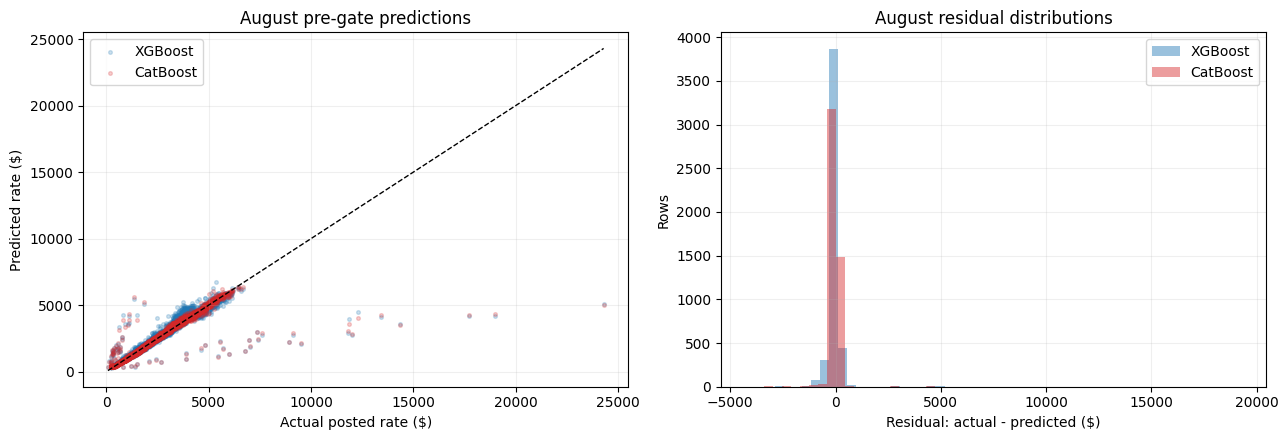

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = {"XGBoost": "#1f77b4", "CatBoost": "#d62728"}
for model_name, predicted in prediction_lookup.items():
    axes[0].scatter(y_comparison_valid, predicted, s=7, alpha=0.22,
                    label=model_name, color=colors[model_name])
    axes[1].hist(y_comparison_valid.to_numpy() - predicted, bins=55,
                 alpha=0.45, label=model_name, color=colors[model_name])
limits = [float(y_comparison_valid.min()), float(y_comparison_valid.max())]
axes[0].plot(limits, limits, "k--", linewidth=1)
axes[0].set(xlabel="Actual posted rate ($)", ylabel="Predicted rate ($)",
            title="August pre-gate predictions")
axes[1].set(xlabel="Residual: actual - predicted ($)", ylabel="Rows",
            title="August residual distributions")
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Tune CatBoost on earlier rolling windows

Six deterministic candidates compare direct and residual targets on June, July, and August. The September-October holdout is used only as the promotion gate.

In [9]:
rolling_folds = []
for months_before_cutoff in (3, 2, 1):
    valid_start = cutoff - pd.DateOffset(months=months_before_cutoff)
    valid_end = valid_start + pd.offsets.MonthEnd(0)
    fold_train = train_raw.loc[train_raw["date"] < valid_start].copy()
    fold_valid = train_raw.loc[train_raw["date"].between(valid_start, valid_end)].copy()
    assert len(fold_train) and len(fold_valid)
    assert fold_train["date"].max() < fold_valid["date"].min()
    assert fold_valid["date"].max() < cutoff
    rolling_folds.append({"valid_month": valid_start.strftime("%Y-%m"),
        "train": fold_train, "valid": fold_valid,
        "X_train": add_features(fold_train, True),
        "X_valid": add_features(fold_valid, True)})

assert len(rolling_folds) == 3
print("Chronological folds verified: 3")
display(pd.DataFrame([{"validation_month": f["valid_month"],
    "train_rows": len(f["train"]), "validation_rows": len(f["valid"]),
    "train_through": f["train"]["date"].max().date(),
    "validation_from": f["valid"]["date"].min().date(),
    "validation_through": f["valid"]["date"].max().date()} for f in rolling_folds]))

TUNING_CANDIDATES = [
    {"name": "direct_baseline_d8", "target_strategy": "direct", "params": dict(BASELINE_CAT_PARAMS)},
    {"name": "direct_rmse_d7_reg", "target_strategy": "direct", "params": dict(
        iterations=850, learning_rate=0.04, depth=7, l2_leaf_reg=10.0,
        loss_function="RMSE", random_strength=0.5, bagging_temperature=0.5)},
    {"name": "direct_mae_d7_reg", "target_strategy": "direct", "params": dict(
        iterations=900, learning_rate=0.04, depth=7, l2_leaf_reg=8.0,
        loss_function="MAE", random_strength=0.5, bagging_temperature=0.5)},
    {"name": "direct_rmse_d9_slow", "target_strategy": "direct", "params": dict(
        iterations=750, learning_rate=0.035, depth=9, l2_leaf_reg=8.0,
        loss_function="RMSE", random_strength=0.75, bagging_temperature=0.75)},
    {"name": "residual_rmse_d7_reg", "target_strategy": "residual", "params": dict(
        iterations=850, learning_rate=0.04, depth=7, l2_leaf_reg=10.0,
        loss_function="RMSE", random_strength=0.5, bagging_temperature=0.5)},
    {"name": "residual_mae_d7_reg", "target_strategy": "residual", "params": dict(
        iterations=900, learning_rate=0.04, depth=7, l2_leaf_reg=8.0,
        loss_function="MAE", random_strength=0.5, bagging_temperature=0.5)},
]

tuning_rows = []
for candidate in TUNING_CANDIDATES:
    for fold_number, fold in enumerate(rolling_folds, 1):
        bundle = fit_cat(fold["X_train"], training_target(fold["train"], candidate["target_strategy"]),
            fold["X_valid"], training_target(fold["valid"], candidate["target_strategy"]),
            model_params=candidate["params"])
        predictions = np.maximum(invert_target(fold["valid"],
            predict_cat(bundle, fold["X_valid"]), candidate["target_strategy"]), POSITIVE_FLOOR)
        scores = metric_row(candidate["name"], fold["valid"][TARGET], predictions)
        tuning_rows.append({"candidate": candidate["name"],
            "target_strategy": candidate["target_strategy"], "fold": fold_number,
            "validation_month": fold["valid_month"], "best_iterations": best_tree_count(bundle),
            "MAE": scores["MAE"], "RMSE": scores["RMSE"], "R2": scores["R2"]})

tuning_results = pd.DataFrame(tuning_rows)
tuning_summary = (tuning_results.groupby(["candidate", "target_strategy"], as_index=False)
    .agg(mean_MAE=("MAE", "mean"), std_MAE=("MAE", "std"),
         mean_RMSE=("RMSE", "mean"), mean_iterations=("best_iterations", "mean"))
    .sort_values(["mean_MAE", "std_MAE"], ignore_index=True))
best_candidate_name = tuning_summary.loc[0, "candidate"]
best_candidate = next(c for c in TUNING_CANDIDATES if c["name"] == best_candidate_name)
print(f"Rolling tuning candidates evaluated: {len(TUNING_CANDIDATES)}")
print(f"Best rolling candidate: {best_candidate_name} ({best_candidate['target_strategy']} target)")
display(tuning_results.style.format({"MAE": "${:,.2f}", "RMSE": "${:,.2f}", "R2": "{:.4f}"}))
display(tuning_summary.style.format({"mean_MAE": "${:,.2f}", "std_MAE": "${:,.2f}",
    "mean_RMSE": "${:,.2f}", "mean_iterations": "{:.0f}"}))

# Freeze iterations from rolling folds before consulting the final gate.
tuned_iterations = int(round(tuning_summary.loc[
    tuning_summary["candidate"].eq(best_candidate_name), "mean_iterations"
].iloc[0]))
baseline_iterations = int(round(tuning_summary.loc[
    tuning_summary["candidate"].eq("direct_baseline_d8"), "mean_iterations"
].iloc[0]))

baseline_holdout_bundle = fit_cat(X_fit_full, y_fit,
    iterations=baseline_iterations, model_params=BASELINE_CAT_PARAMS)
cat_holdout_predictions = np.maximum(
    predict_cat(baseline_holdout_bundle, X_holdout_full), POSITIVE_FLOOR)
tuned_holdout_bundle = fit_cat(X_fit_full,
    training_target(fit_frame, best_candidate["target_strategy"]),
    iterations=tuned_iterations, model_params=best_candidate["params"])
tuned_holdout_predictions = np.maximum(invert_target(holdout_frame,
    predict_cat(tuned_holdout_bundle, X_holdout_full), best_candidate["target_strategy"]),
    POSITIVE_FLOOR)

baseline_holdout_mae = mean_absolute_error(y_holdout, cat_holdout_predictions)
tuned_holdout_mae = mean_absolute_error(y_holdout, tuned_holdout_predictions)
promoted = tuned_holdout_mae < baseline_holdout_mae
if promoted:
    production_params = dict(best_candidate["params"])
    production_target_strategy = best_candidate["target_strategy"]
    full_best_iterations = tuned_iterations
    promotion_label = "PROMOTED"
else:
    production_params = dict(BASELINE_CAT_PARAMS)
    production_target_strategy = "direct"
    full_best_iterations = baseline_iterations
    promotion_label = "RETAINED BASELINE"

winner_name = "CatBoost"
tuning_promotion_metrics = pd.DataFrame([
    metric_row("CatBoost baseline", y_holdout, cat_holdout_predictions),
    metric_row(f"Rolling-selected: {best_candidate_name}", y_holdout, tuned_holdout_predictions),
]).sort_values("MAE", ignore_index=True)
print(f"Frozen rolling iterations: tuned={tuned_iterations}, baseline={baseline_iterations}")
print("Final gate fits used early stopping: False")
print(f"Final holdout promotion: {promotion_label}")
print(f"Production target strategy: {production_target_strategy}")
print(f"Production trees/iterations: {full_best_iterations}")
display(tuning_promotion_metrics.style.format({"MAE": "${:,.2f}", "RMSE": "${:,.2f}", "R2": "{:.4f}"}))

Chronological folds verified: 3


,validation_month,train_rows,validation_rows,train_through,validation_from,validation_through
0,2025-06,24023,4783,2025-05-31,2025-06-01,2025-06-30
1,2025-07,28806,4912,2025-06-30,2025-07-01,2025-07-31
2,2025-08,33718,4759,2025-07-31,2025-08-01,2025-08-31


Rolling tuning candidates evaluated: 6
Best rolling candidate: direct_mae_d7_reg (direct target)


,candidate,target_strategy,fold,validation_month,best_iterations,MAE,RMSE,R2
0,direct_baseline_d8,direct,1,2025-06,319,$138.23,$704.43,0.8077
1,direct_baseline_d8,direct,2,2025-07,80,$148.13,$638.47,0.8200
2,direct_baseline_d8,direct,3,2025-08,189,$123.18,$618.47,0.8241
3,direct_rmse_d7_reg,direct,1,2025-06,356,$137.20,$705.82,0.8070
4,direct_rmse_d7_reg,direct,2,2025-07,143,$144.68,$637.13,0.8207
5,direct_rmse_d7_reg,direct,3,2025-08,208,$122.89,$617.87,0.8245
6,direct_mae_d7_reg,direct,1,2025-06,177,$151.08,$709.95,0.8047
7,direct_mae_d7_reg,direct,2,2025-07,218,$124.22,$632.06,0.8236
8,direct_mae_d7_reg,direct,3,2025-08,550,$103.76,$615.52,0.8258
9,direct_rmse_d9_slow,direct,1,2025-06,446,$143.77,$708.62,0.8054


,candidate,target_strategy,mean_MAE,std_MAE,mean_RMSE,mean_iterations
0,direct_mae_d7_reg,direct,$126.35,$23.73,$652.51,315
1,direct_rmse_d7_reg,direct,$134.92,$11.07,$653.61,236
2,direct_baseline_d8,direct,$136.51,$12.56,$653.79,196
3,direct_rmse_d9_slow,direct,$141.80,$15.45,$655.74,255
4,residual_rmse_d7_reg,residual,$156.94,$59.98,$663.93,316
5,residual_mae_d7_reg,residual,$182.72,$100.45,$670.75,471


Frozen rolling iterations: tuned=315, baseline=196
Final gate fits used early stopping: False
Final holdout promotion: PROMOTED
Production target strategy: direct
Production trees/iterations: 315


,model,MAE,RMSE,R2
0,Rolling-selected: direct_mae_d7_reg,$130.25,$640.59,0.8238
1,CatBoost baseline,$131.63,$638.92,0.8247


## 8. Check the selected model on December-compatible features

The separate chart input intentionally omits coordinates, market index, and quote signal. A second instance of the selected algorithm is therefore evaluated using only fields available in that file. This reduced metric is reported separately and does not alter the fair full-feature winner selection.

In [10]:
X_fit_reduced = add_features(fit_frame, False)
X_holdout_reduced = add_features(holdout_frame, False)
# December lacks quote_signal. Reuse the pre-gate frozen iteration count and direct target.
reduced_best_iterations = full_best_iterations
reduced_holdout_bundle = fit_cat(X_fit_reduced, y_fit,
    iterations=reduced_best_iterations, model_params=production_params)
reduced_holdout_predictions = np.maximum(
    predict_cat(reduced_holdout_bundle, X_holdout_reduced), POSITIVE_FLOOR)
reduced_metrics = pd.DataFrame([
    metric_row("CatBoost — reduced December features", y_holdout, reduced_holdout_predictions)
])
display(reduced_metrics.style.format({"MAE": "${:,.2f}", "RMSE": "${:,.2f}", "R2": "{:.4f}"}))

,model,MAE,RMSE,R2
0,CatBoost — reduced December features,$131.72,$641.52,0.8233


## 9. Refit the selected algorithm and generate deliverables

The full selected model is refit on all 48,000 labeled rows for the 12,000 official validation loads. The reduced selected model is refit on all labeled rows for the fixed 31-day December chart input.

In [11]:
X_all_full = add_features(train_raw, True)
X_validation_full = add_features(validation_raw, True)
y_all = train_raw[TARGET].astype(float)
final_full_bundle = fit_cat(X_all_full,
    training_target(train_raw, production_target_strategy),
    iterations=full_best_iterations, model_params=production_params)
validation_predictions = invert_target(validation_raw,
    predict_cat(final_full_bundle, X_validation_full), production_target_strategy)
validation_predictions = np.maximum(np.asarray(validation_predictions, dtype=float), POSITIVE_FLOOR)
assert len(validation_predictions) == len(validation_raw) == 12_000
assert np.isfinite(validation_predictions).all() and (validation_predictions > 0).all()
print(f"Final full model: CatBoost, target: {production_target_strategy}, trees/iterations: {full_best_iterations}")

Final full model: CatBoost, target: direct, trees/iterations: 315


In [12]:
prediction_by_id = pd.Series(
    validation_predictions,
    index=validation_raw["load_id"].astype(str),
)
validation_output = prediction_template[["load_id"]].copy()
validation_output["predicted_rate"] = validation_output["load_id"].map(prediction_by_id)

assert list(validation_output.columns) == ["load_id", "predicted_rate"]
assert len(validation_output) == 12_000
assert validation_output["load_id"].is_unique
assert set(validation_output["load_id"]) == {f"TE-{number:06d}" for number in range(1, 12_001)}
assert np.isfinite(validation_output["predicted_rate"]).all()
assert (validation_output["predicted_rate"] > 0).all()

validation_output.to_csv(ROOT / "validation_predictions.csv", index=False, float_format="%.2f")
display(validation_output.head())

,load_id,predicted_rate
0,TE-000001,903.254597
1,TE-000002,4970.035159
2,TE-000003,5235.540225
3,TE-000004,4046.392780
4,TE-000005,1830.382355


In [13]:
X_all_reduced = add_features(train_raw, False)
X_december_reduced = add_features(december_raw, False)
final_reduced_bundle = fit_cat(X_all_reduced, y_all,
    iterations=reduced_best_iterations, model_params=production_params)
december_predictions = predict_cat(final_reduced_bundle, X_december_reduced)
december_output = december_raw.copy()
december_output["date"] = december_output["date"].dt.strftime("%Y-%m-%d")
december_output["predicted_rate"] = np.maximum(np.asarray(december_predictions, dtype=float), POSITIVE_FLOOR)
expected_december_columns = ["pickup", "delivery", "distance", "equipment", "weight", "date", "predicted_rate"]
assert list(december_output.columns) == expected_december_columns
assert len(december_output) == 31
assert december_output["pickup"].eq("Lexington").all()
assert december_output["delivery"].eq("Fort Wayne").all()
assert np.isclose(december_output["distance"], 360).all()
assert december_output["equipment"].eq("Dry Van").all()
assert np.isclose(december_output["weight"], 32_000).all()
assert np.isfinite(december_output["predicted_rate"]).all()
assert (december_output["predicted_rate"] > 0).all()
data_directory = ROOT / "data"
data_directory.mkdir(exist_ok=True)
december_output.to_csv(data_directory / "december_chart_inputs.csv", index=False, float_format="%.2f")
display(december_output.head())

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,835.256481
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,842.785235
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,849.770006
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,849.648086
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,848.316138


## 10. Final integrity checks and summary

The supplied scorer remains untouched. The two CSVs now have the exact schemas and positive finite predictions required by `Score.py`.

In [14]:
assert (ROOT / "validation_predictions.csv").is_file()
assert (ROOT / "data" / "december_chart_inputs.csv").is_file()
summary = pd.concat([
    metrics.assign(feature_set="August model-family comparison"),
    tuning_promotion_metrics.assign(feature_set="full promotion gate"),
    reduced_metrics.assign(feature_set="reduced (December compatible)"),
], ignore_index=True)
display(summary[["model", "feature_set", "MAE", "RMSE", "R2"]].style.format({
    "MAE": "${:,.2f}", "RMSE": "${:,.2f}", "R2": "{:.4f}"}))
print(f"Winner: CatBoost ({promotion_label})")
print("Created validation_predictions.csv")
print("Created data/december_chart_inputs.csv")

,model,feature_set,MAE,RMSE,R2
0,CatBoost,August model-family comparison,$123.18,$618.47,0.8241
1,XGBoost,August model-family comparison,$175.80,$643.33,0.8097
2,Rolling-selected: direct_mae_d7_reg,full promotion gate,$130.25,$640.59,0.8238
3,CatBoost baseline,full promotion gate,$131.63,$638.92,0.8247
4,CatBoost — reduced December features,reduced (December compatible),$131.72,$641.52,0.8233


Winner: CatBoost (PROMOTED)
Created validation_predictions.csv
Created data/december_chart_inputs.csv
